## **EDA**
---
* OBJECTIVE:  

In [1]:
#Libraries
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from scipy.stats import chi2_contingency
import itertools
from scipy.stats import f_oneway
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


In [2]:
df_deliv_v1 = pd.read_csv(r"/home/elias/proyectos/delivery-time-test/data/raw/Food_Delivery_Times.csv")

In [3]:
df_deliv_v1.shape

(1000, 9)

**SHAPE** of (1000, 9)... the models could overfit. I'll take this on mind

In [4]:
df_deliv_v1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB


## **NULLS**
---

In [17]:
df_deliv_v1.isna().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

Missing data from **Weather**, **Traffic_Level**, **Time_of_Day**, **Courier_Experience_yrs**
No nulls on the VR 

## **DUPLICATES**
--- 

In [5]:
df_deliv_v1.duplicated().sum()

np.int64(0)

NO duplicated ROWS

## **DISTRIBUTIONS**
---

In [6]:
df_deliv_v1.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [7]:
df_deliv_v1["Order_ID"] = df_deliv_v1["Order_ID"].astype(str) 

In [8]:
df_deliv_v1.describe()

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,970.000000,1000.000000
mean,10.059970,16.982000,4.579381,56.732000
std,5.696656,7.204553,2.914394,22.070915
min,0.590000,5.000000,0.000000,8.000000
25%,5.105000,11.000000,2.000000,41.000000
50%,10.190000,17.000000,5.000000,55.500000
75%,15.017500,23.000000,7.000000,71.000000
max,19.990000,29.000000,9.000000,153.000000


## **NUMERICAL VARIABLES**

DROPPING MISSING VALUES

Distance_km: mean = 10.05997, median = 10.19, std = 5.696655526120856
Preparation_Time_min: mean = 16.982, median = 17.0, std = 7.204552837031704
Courier_Experience_yrs: mean = 4.579381443298969, median = 5.0, std = 2.9143939478823078
Delivery_Time_min: mean = 56.732, median = 55.5, std = 22.07091528009886


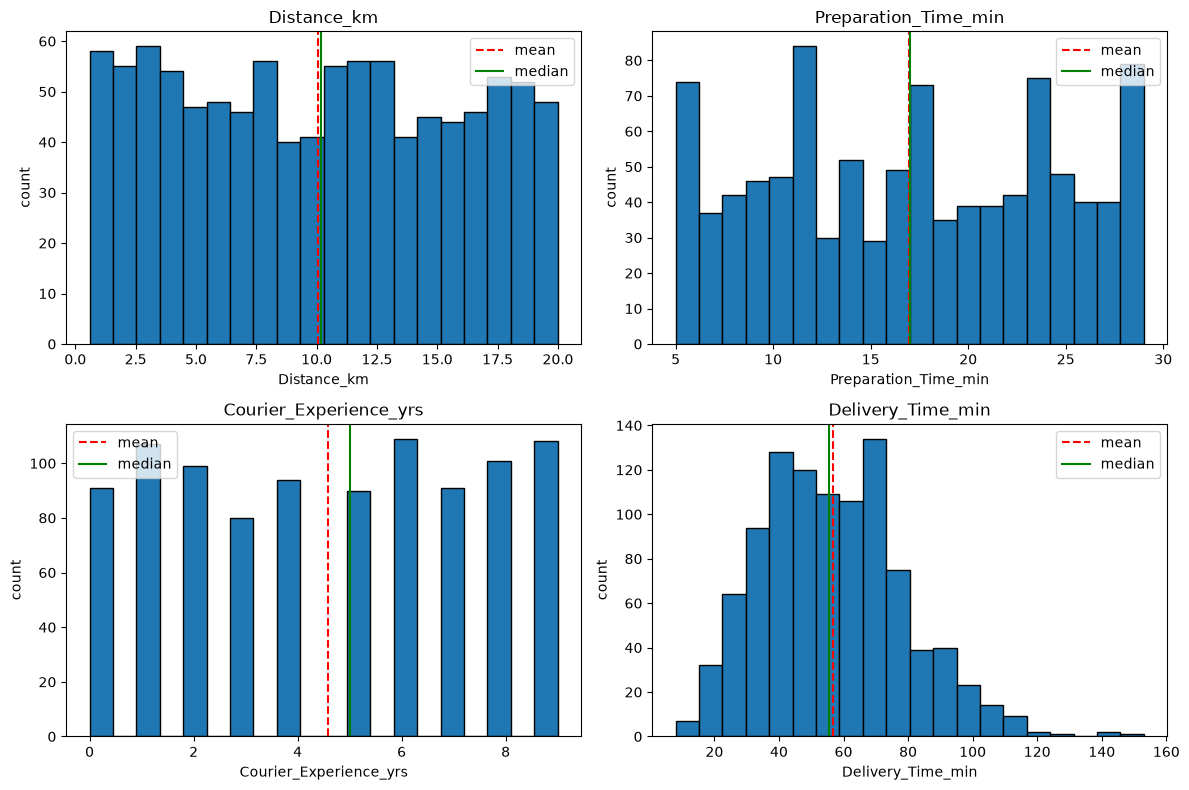

In [9]:
num_cols = df_deliv_v1.select_dtypes(include=["int64","float64"])
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i in num_cols:
    mean = df_deliv_v1[i].mean()
    median = df_deliv_v1[i].median()
    std = df_deliv_v1[i].std()
    print(f"{i}: mean = {mean}, median = {median}, std = {std}")
for idx, cols in enumerate(num_cols):
    data = num_cols[cols].dropna()
    axes[idx].hist(data, bins=20, edgecolor="black")
    axes[idx].axvline(data.mean(), color="red", linestyle="--", label="mean")
    axes[idx].axvline(data.median(), color="green", linestyle="-", label="median")
    axes[idx].set_title(cols)
    axes[idx].set_xlabel(cols)
    axes[idx].set_ylabel("count")
    axes[idx].legend()

plt.tight_layout()
plt.show()

In [10]:
df_deliv_v1["Courier_Experience_yrs"].unique().tolist()

[1.0, 2.0, 5.0, 9.0, 6.0, 4.0, 7.0, nan, 3.0, 8.0, 0.0]

Only int values for courier_experience_yrs

* The three features **distance_km**, **Preparation_Time_min**, **Courier_Experience_yrs** are close to uniform.
* The target is bell-shaped with a mild right tail

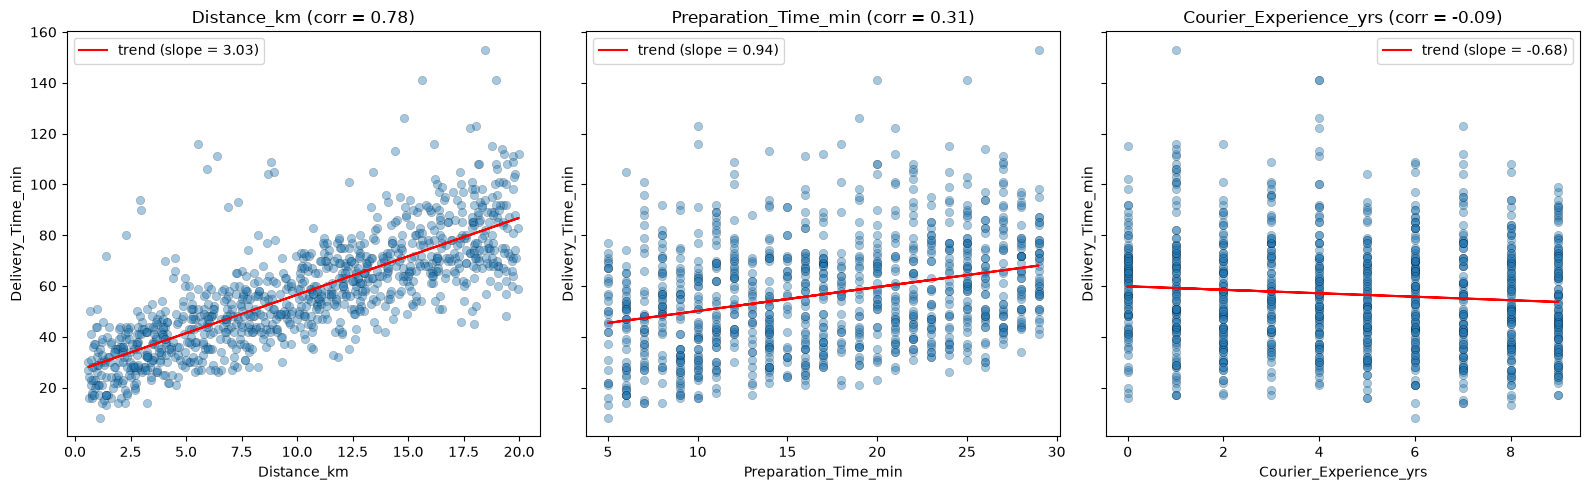

In [13]:
delivery_time = "Delivery_Time_min"
feature_cols = num_cols.drop(columns="Delivery_Time_min")
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
axes = axes.flatten()

for idx, cols in enumerate(feature_cols):
    data = df_deliv_v1[[cols, delivery_time]].dropna()
    corr = data[cols].corr(data[delivery_time])
    slope, intercept = np.polyfit(data[cols], data[delivery_time], 1)
    axes[idx].scatter(data[cols], data[delivery_time], alpha=0.4, edgecolor="black", linewidth=0.3)
    axes[idx].plot(data[cols], slope * data[cols] + intercept, color="red", label=f"trend (slope = {slope:.2f})")
    axes[idx].set_title(f"{cols} (corr = {corr:.2f})")
    axes[idx].set_xlabel(cols)
    axes[idx].set_ylabel(delivery_time)
    axes[idx].legend()

plt.tight_layout()
plt.show()

**Numeric variables vs Delivery_Time_min***
* Distance_km: strong positive correlation (0.78). Each extra km adds about 3 minutes (slope 3.03). It is the main driver of delivery time.
* Preparation_Time_min: weak-to-moderate positive correlation (0.31). Each extra preparation minute adds about 0.94 minutes to the delivery time, almost one for one.
* Courier_Experience_yrs: almost no correlation (-0.09). The slope (-0.68 min per year) is small, so experience has only a minor effect.

In [37]:
# IQR rule on the target
q1 = df_deliv_v1[delivery_time].quantile(0.25)
q3 = df_deliv_v1[delivery_time].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Fences: lower = {lower_fence}, upper = {upper_fence}")

below = df_deliv_v1[df_deliv_v1[delivery_time] < lower_fence]
above = df_deliv_v1[df_deliv_v1[delivery_time] > upper_fence]
print(f"Below the lower fence: {len(below)}")
print(f"Above the upper fence: {len(above)}")
print(above.sort_values(delivery_time, ascending=False))

Q1 = 41.0, Q3 = 71.0, IQR = 30.0
Fences: lower = -4.0, upper = 116.0
Below the lower fence: 0
Above the upper fence: 6
    Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
379      814        18.46   Clear           NaN         NaN      Scooter   
127      446        18.97   Clear           Low     Evening          Car   
452      394        15.64   Rainy           Low         NaN         Bike   
784      385        14.83   Rainy           Low     Morning          Car   
29       948        18.05   Clear        Medium     Evening      Scooter   
924      428        17.81   Windy          High     Evening         Bike   

     Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
379                    29                     1.0                153  
127                    25                     4.0                141  
452                    20                     4.0                141  
784                    19                     4.0               

In [38]:
lr = LinearRegression().fit(df_deliv_v1[["Distance_km"]], df_deliv_v1[delivery_time])
df_check = df_deliv_v1.copy()
df_check["predicted"] = lr.predict(df_check[["Distance_km"]])
df_check["residual"] = df_check[delivery_time] - df_check["predicted"]
df_check["residual_std"] = df_check["residual"] / df_check["residual"].std()

print(df_check.loc[above.index, ["Distance_km", delivery_time, "predicted", "residual", "residual_std"]]
      .sort_values("residual_std", ascending=False).round(1))

     Distance_km  Delivery_Time_min  predicted  residual  residual_std
379         18.5                153       82.1      70.9           5.1
452         15.6                141       73.6      67.4           4.9
127         19.0                141       83.7      57.3           4.2
784         14.8                126       71.2      54.8           4.0
29          18.0                123       80.9      42.1           3.1
924         17.8                122       80.2      41.8           3.0


## **CATEGORICAL VARIABLES** 

In [14]:
df_deliv_v1.describe(exclude=["int64","float64"])

,Order_ID,Weather,Traffic_Level,Time_of_Day,Vehicle_Type
count,1000,970,970,970,1000
unique,1000,5,3,4,3
top,522,Clear,Medium,Morning,Bike
freq,1,470,390,308,503


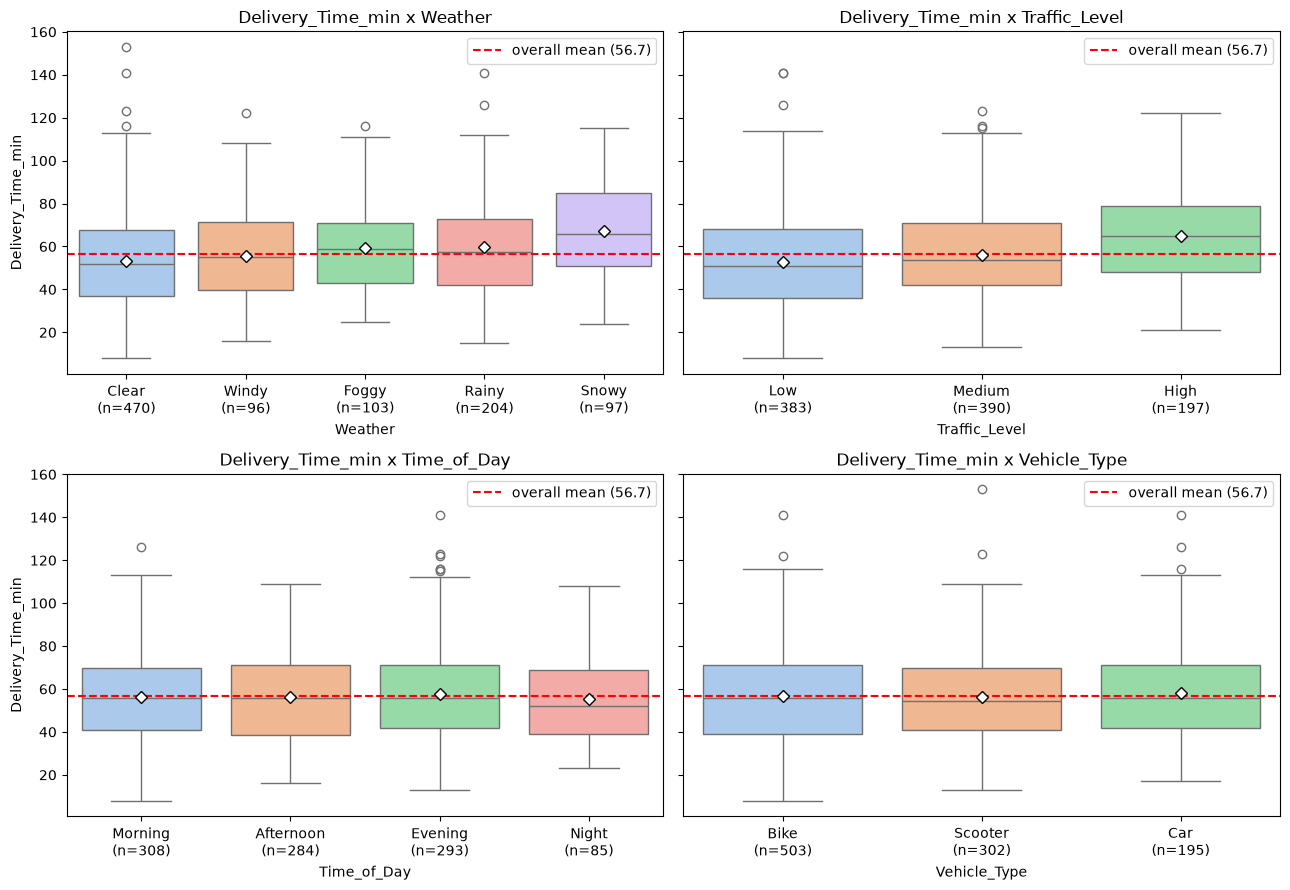

In [15]:

cat_cols = df_deliv_v1.select_dtypes(exclude=["int64","float64"]).drop(columns = ["Order_ID"]).columns.to_list()

orders = {
    "Weather":       ["Clear","Windy","Foggy","Rainy","Snowy"],
    "Traffic_Level": ["Low","Medium","High"],
    "Time_of_Day":   ["Morning","Afternoon","Evening","Night"],
    "Vehicle_Type":  ["Bike","Scooter","Car"],
}

overall_mean = df_deliv_v1[delivery_time].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
axes = axes.flatten()

for idx, cat in enumerate(cat_cols):
    data = df_deliv_v1.dropna(subset=[cat])
    counts = data[cat].value_counts()
    sns.boxplot(x=cat, y=delivery_time, data=data, order=orders[cat],
                hue=cat, hue_order=orders[cat], palette="pastel", legend=False,
                showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                ax=axes[idx])
    axes[idx].axhline(overall_mean, color="red", linestyle="--", label=f"overall mean ({overall_mean:.1f})")
    axes[idx].set_xticks(range(len(orders[cat])))
    axes[idx].set_xticklabels([f"{c}\n(n={counts[c]})" for c in orders[cat]])
    axes[idx].set_title(f"{delivery_time} x {cat}")
    axes[idx].set_xlabel(cat)
    axes[idx].set_ylabel(delivery_time)
    axes[idx].legend()

plt.tight_layout()
plt.show()

* Traffic: the whole box moves up from Low (median about 51) to High (about 65).
* Weather: the Snowy box also sits higher (median about 66 vs about 52 for Clear), by about the same amount as High vs Low traffic. It looks less important only because Snowy is rarer (97 rows) and the other weather types overlap.
* Time of day and vehicle: the boxes overlap almost fully. No visible effec

/tmp/ipykernel_34606/911854974.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat, y=delivery_time, data=data, order=orders[cat],
/tmp/ipykernel_34606/911854974.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat, y=delivery_time, data=data, order=orders[cat],
/tmp/ipykernel_34606/911854974.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat, y=delivery_time, data=data, order=orders[cat],
/tmp/ipykernel_34606/911854974.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.

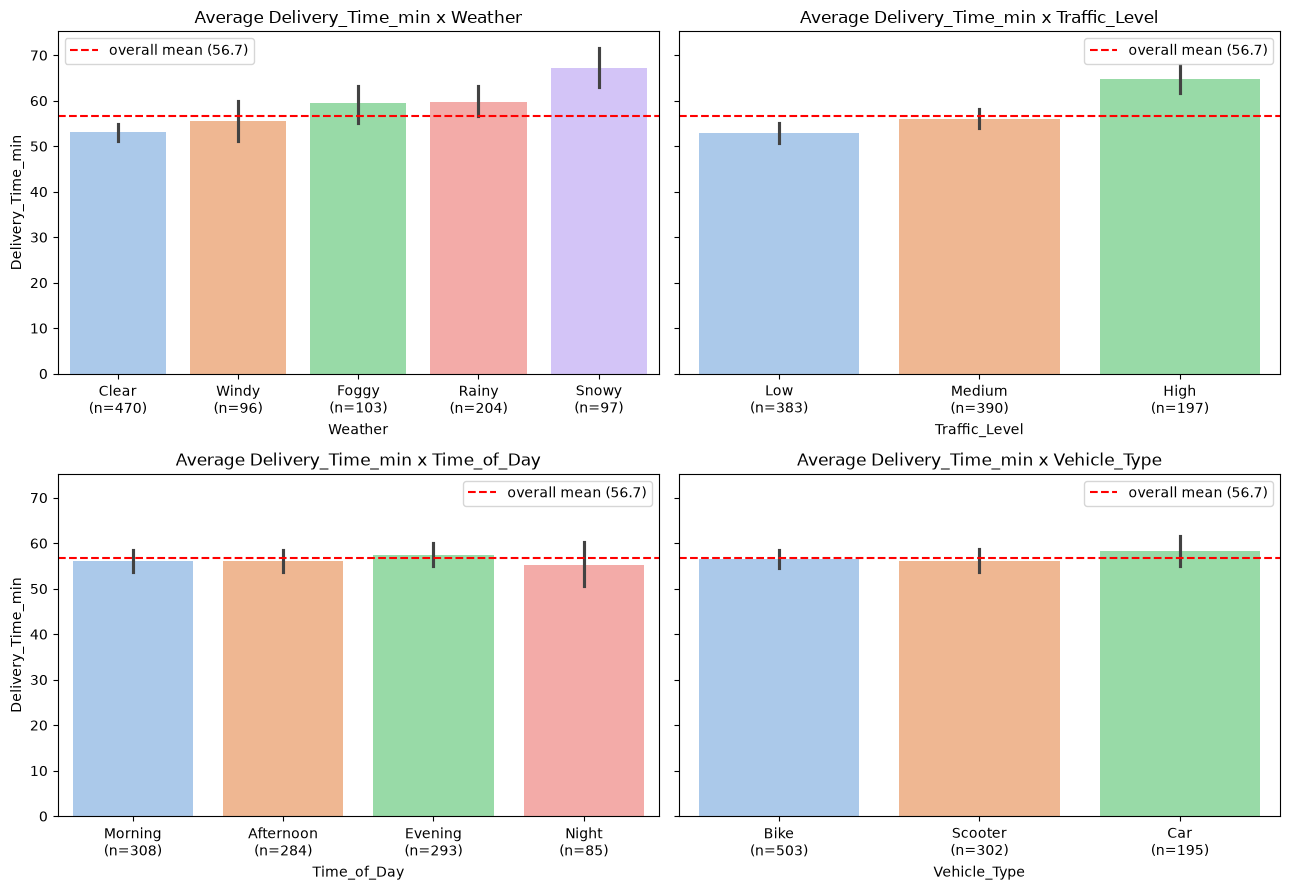

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
axes = axes.flatten()
for idx, cat in enumerate(cat_cols):
    data = df_deliv_v1.dropna(subset=[cat])         
    counts = data[cat].value_counts()
    sns.barplot(x=cat, y=delivery_time, data=data, order=orders[cat],
                errorbar=("ci", 95), ax=axes[idx], palette="pastel")
    axes[idx].axhline(overall_mean, color="red", linestyle="--", label=f"overall mean ({overall_mean:.1f})")
    axes[idx].set_xticks(range(len(orders[cat])))
    axes[idx].set_xticklabels([f"{c}\n(n={counts[c]})" for c in orders[cat]])
    axes[idx].set_title(f"Average {delivery_time} x {cat}")
    axes[idx].set_xlabel(cat)
    axes[idx].set_ylabel(delivery_time)
    axes[idx].legend()

plt.tight_layout()
plt.show()

NO DUPLICATED Values in  ORDER_ID.

I'LL CHECKED IF THE WEATHER HAS SOME KIND OF EFFECT ON THE TRAFFIC_LEVEL

In [17]:
print(pd.crosstab(df_deliv_v1["Weather"],df_deliv_v1["Traffic_Level"],normalize="index").round(2)*100)

Traffic_Level  High   Low  Medium
Weather                          
Clear          18.0  39.0    43.0
Foggy          21.0  46.0    33.0
Rainy          22.0  40.0    37.0
Snowy          21.0  47.0    32.0
Windy          25.0  28.0    47.0


In [18]:
for a, b in itertools.combinations(cat_cols, 2):
    ct = pd.crosstab(df_deliv_v1[a], df_deliv_v1[b])
    chi2, p, dof, exp = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{a} x {b}: V = {cramers_v:.3f}, p-value = {p:.3f}")

Weather x Traffic_Level: V = 0.082, p-value = 0.121
Weather x Time_of_Day: V = 0.053, p-value = 0.798
Weather x Vehicle_Type: V = 0.075, p-value = 0.206
Traffic_Level x Time_of_Day: V = 0.053, p-value = 0.497
Traffic_Level x Vehicle_Type: V = 0.056, p-value = 0.198
Time_of_Day x Vehicle_Type: V = 0.080, p-value = 0.056


Weather does not have a meaningful effect on traffic level (V = 0.08, p = 0.12).</p>
None of the categorical pairs are associated. </p>
So the four categorical variables carry separate information, and no one of them repeats another. 
That is good for an linear model: each coefficient can be read on its own.

## **ANOVA** & **CORRELATION HEATMAP**

In [40]:
def full_check(df:pd.DataFrame,
              label:str):
    """
    FUNCTION that helps apply ANOVA, R**2, correlation heatmap and the IQR check of the target
    PARAMS:
        1.df: Dataframe with the differents variables to analyze
        2.label: the version name that will be wrote in the title of the heatmap 
    RETURNS:
        1.anova_df: eta squared and p-value of each categorical variable (raw time and time without the distance effect)
        2.r2_df: R**2 of linear models with different sets of features
        3.outliers_df: rows above the IQR upper fence, with the time that the distance predicts and the residual
    """
    plt.figure(figsize=(8,6))
    cols = [cols for cols in df.select_dtypes(include=["int64","float64"]).columns if "Order_ID" not in cols]
    sns.heatmap(df[cols].corr(),annot=True,fmt=".2f",cmap="coolwarm", vmin=-1, vmax=1)
    plt.title(f"Correlation heatmap ({label})")
    plt.tight_layout()
    plt.show()

    X = df[["Distance_km"]]
    y = df[delivery_time]
    lr = LinearRegression().fit(X,y)
    r2_dist = r2_score(y,lr.predict(X))
    print(f"{label} R2 of Distance_km = {r2_dist:.4f}")
    residual = y - lr.predict(X)

    # IQR rule on the target
    q1 = y.quantile(0.25)
    q3 = y.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    print(f"{label} Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
    print(f"{label} Fences: lower = {lower_fence}, upper = {upper_fence}")
    print(f"{label} Below the lower fence: {(y < lower_fence).sum()} | Above the upper fence: {(y > upper_fence).sum()}")


    above = df[y > upper_fence].copy()
    above["predicted"] = lr.predict(above[["Distance_km"]])
    above["residual"] = above[delivery_time] - above["predicted"]
    above["residual_std"] = above["residual"] / residual.std()
    outliers_df = (above[["Distance_km", delivery_time, "predicted", "residual", "residual_std"]]
                   .sort_values("residual_std", ascending=False).round(1))
    
    rows = []
    for cat in cat_cols:
        data = df.dropna(subset=[cat]).copy()
        data["residual_distance"] = residual.loc[data.index]
        for target in [delivery_time, "residual_distance"]:
            groups = [g[target].values for _, g in data.groupby(cat)]
            f_stat, p = f_oneway(*groups)
            ssb = sum(len(g) * (g.mean() - data[target].mean()) ** 2 for g in groups)
            sst = ((data[target] - data[target].mean()) ** 2).sum()
            rows.append({"variable": cat, "target": target, "eta_squared": ssb / sst, "p_value": p})
    anova_df = pd.DataFrame(rows).pivot(index="variable", columns="target", values=["eta_squared", "p_value"]).round(4)

    feature_sets = {
        "Distance":                          ["Distance_km"],
        "+ Traffic":                         ["Distance_km", "Traffic_Level"],
        "+ Weather":                         ["Distance_km", "Weather"],
        "+ Traffic + Weather":               ["Distance_km", "Traffic_Level", "Weather"],
        "+ Preparation time":                ["Distance_km", "Preparation_Time_min"],
        "+ Preparation + Traffic + Weather": ["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather"],
        "All features":                      ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs",
                                              "Traffic_Level", "Weather", "Time_of_Day", "Vehicle_Type"],
    }
    r2_rows = []
    for name, feats in feature_sets.items():
        data = df[feats + [delivery_time]].dropna()
        X_set = pd.get_dummies(data[feats], drop_first=True).astype(float)
        y_set = data[delivery_time]
        r2 = r2_score(y_set, LinearRegression().fit(X_set, y_set).predict(X_set))
        r2_rows.append({"features": name, "n_rows": len(data), f"R2 ({label})": round(r2, 3)})
    r2_df = pd.DataFrame(r2_rows)

    return anova_df, r2_df, outliers_df

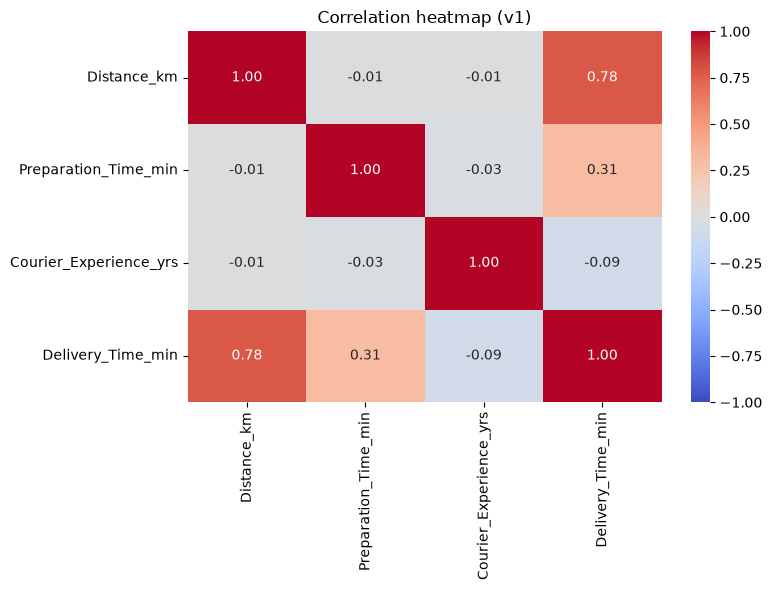

v1 R2 of Distance_km = 0.6100
v1 Q1 = 41.0, Q3 = 71.0, IQR = 30.0
v1 Fences: lower = -4.0, upper = 116.0
v1 Below the lower fence: 0 | Above the upper fence: 6
                    eta_squared                             p_value  \
target        Delivery_Time_min residual_distance Delivery_Time_min   
variable                                                              
Time_of_Day              0.0011            0.0056            0.7765   
Traffic_Level            0.0400            0.0879            0.0000   
Vehicle_Type             0.0012            0.0008            0.5549   
Weather                  0.0415            0.0606            0.0000   

                                 
target        residual_distance  
variable                         
Time_of_Day              0.1403  
Traffic_Level            0.0000  
Vehicle_Type             0.6686  
Weather                  0.0000  
                            features  n_rows  R2 (v1)
0                           Distance    1000    0.

In [46]:
anova_v1, r2_v1, outliers_v1 = full_check(df_deliv_v1, "v1")
print(anova_v1)
print(r2_v1)
print(outliers_v1)

In [47]:
print(df_deliv_v1[(df_deliv_v1["Distance_km"] < 6) & (df_deliv_v1[delivery_time] > 90)])

    Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
140       45         5.55   Foggy          High     Evening         Bike   
570      150         5.93   Foggy          High         NaN      Scooter   
877      813         2.93   Clear        Medium     Morning         Bike   

     Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
140                    18                     1.0                116  
570                    27                     1.0                106  
877                    24                     8.0                 94  


* The distance in km explains the 61% of the variance can be explained by the Distance_km feature, also as I mentioned before the correlation is higher than in any other feature, for the linear regression model will be an important feature.</p> 
* the three numeric features are almost uncorrelated with each other (-0.01 to -0.03). That means no multicollinearity among the numeric features, so each coefficient in the linear model can be read on its own.</p>
* A linear model with all features reaches R² of about 0.79, so about 21% of the variance stays unexplained.</p>
* The spread of the delivery time grows with the distance, and a few trips are much slower than expected. I'll check them in the error analysis.</p>

## VERSION 2: FILLING THE MISSING VALUES

In [21]:
df_deliv_v2 = df_deliv_v1.copy()
median_courier_exp =  df_deliv_v2["Courier_Experience_yrs"].median()
df_deliv_v2["Courier_Experience_yrs"] = df_deliv_v2["Courier_Experience_yrs"].fillna(median_courier_exp)
for cat in ["Weather", "Traffic_Level", "Time_of_Day"]:
    df_deliv_v2.loc[df_deliv_v2[cat].isna(),f"{cat}"] = "Missing"
print(df_deliv_v2.isna().sum())
print(df_deliv_v2["Traffic_Level"].value_counts()) 

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64
Traffic_Level
Medium     390
Low        383
High       197
Missing     30
Name: count, dtype: int64


I want to test everything that I did before but with tis new DF

## NUMERICAL VARIABLES V2

Distance_km: mean = 10.05997, median = 10.19, std = 5.696655526120856
Preparation_Time_min: mean = 16.982, median = 17.0, std = 7.204552837031704
Courier_Experience_yrs: mean = 4.592, median = 5.0, std = 2.8711983177376967
Delivery_Time_min: mean = 56.732, median = 55.5, std = 22.07091528009886


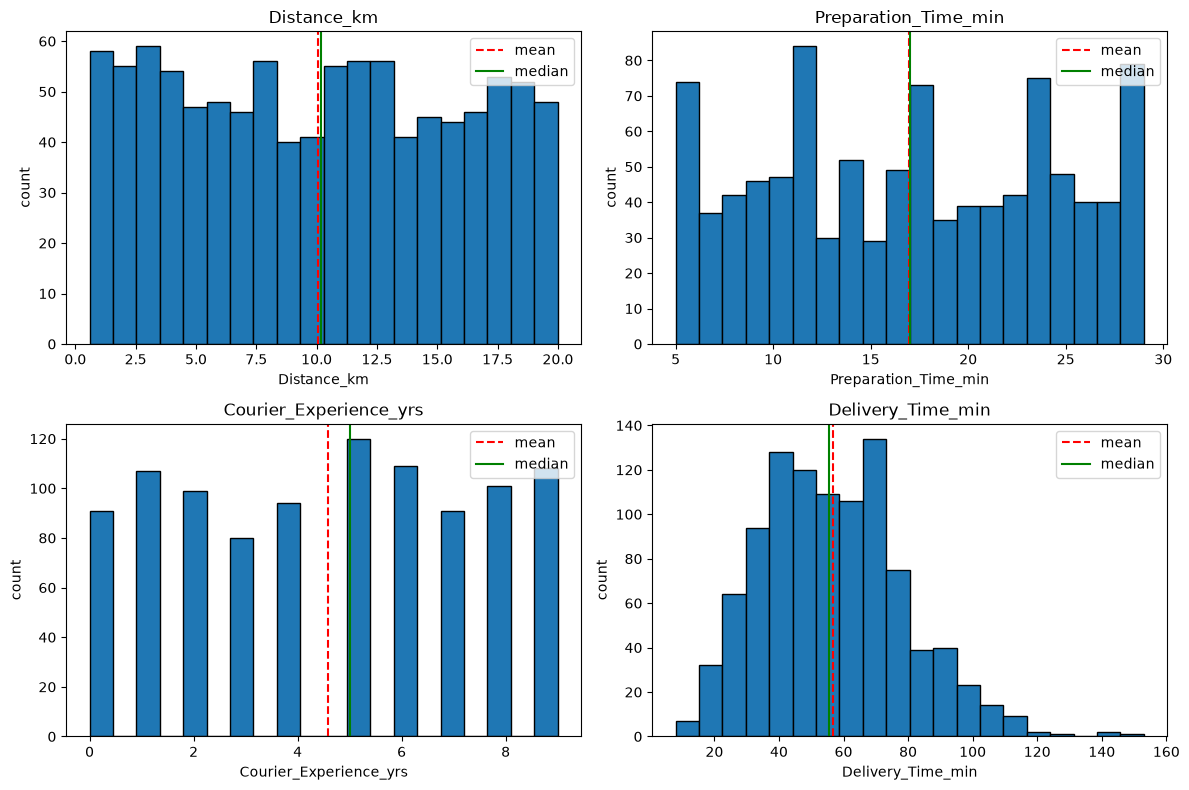

In [22]:
num_cols = df_deliv_v2.select_dtypes(include=["int64","float64"])
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i in num_cols:
    mean = df_deliv_v2[i].mean()
    median = df_deliv_v2[i].median()
    std = df_deliv_v2[i].std()
    print(f"{i}: mean = {mean}, median = {median}, std = {std}")
for idx, cols in enumerate(num_cols):
    data = num_cols[cols].dropna()
    axes[idx].hist(data, bins=20, edgecolor="black")
    axes[idx].axvline(data.mean(), color="red", linestyle="--", label="mean")
    axes[idx].axvline(data.median(), color="green", linestyle="-", label="median")
    axes[idx].set_title(cols)
    axes[idx].set_xlabel(cols)
    axes[idx].set_ylabel("count")
    axes[idx].legend()

plt.tight_layout()
plt.show()

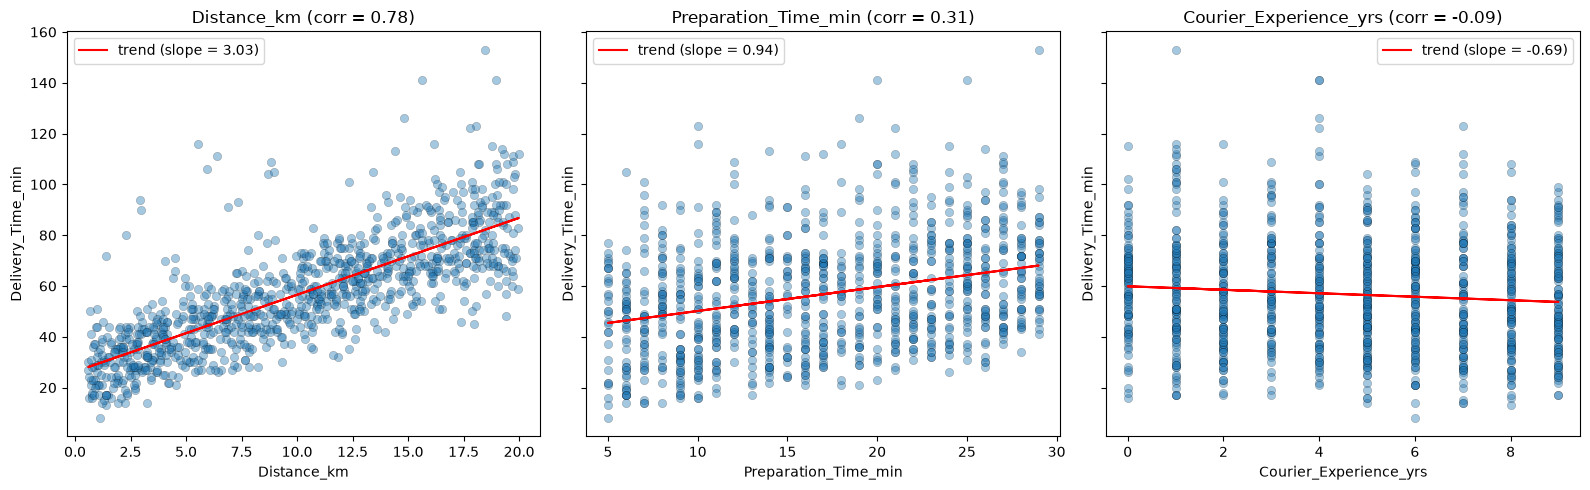

In [23]:
delivery_time = "Delivery_Time_min"
feature_cols = num_cols.drop(columns="Delivery_Time_min")
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
axes = axes.flatten()

for idx, cols in enumerate(feature_cols):
    data = df_deliv_v2[[cols, delivery_time]]
    corr = data[cols].corr(data[delivery_time])
    slope, intercept = np.polyfit(data[cols], data[delivery_time], 1)
    axes[idx].scatter(data[cols], data[delivery_time], alpha=0.4, edgecolor="black", linewidth=0.3)
    axes[idx].plot(data[cols], slope * data[cols] + intercept, color="red", label=f"trend (slope = {slope:.2f})")
    axes[idx].set_title(f"{cols} (corr = {corr:.2f})")
    axes[idx].set_xlabel(cols)
    axes[idx].set_ylabel(delivery_time)
    axes[idx].legend()
plt.tight_layout()
plt.show()

## **CATEGORICAL VARIABLES** 

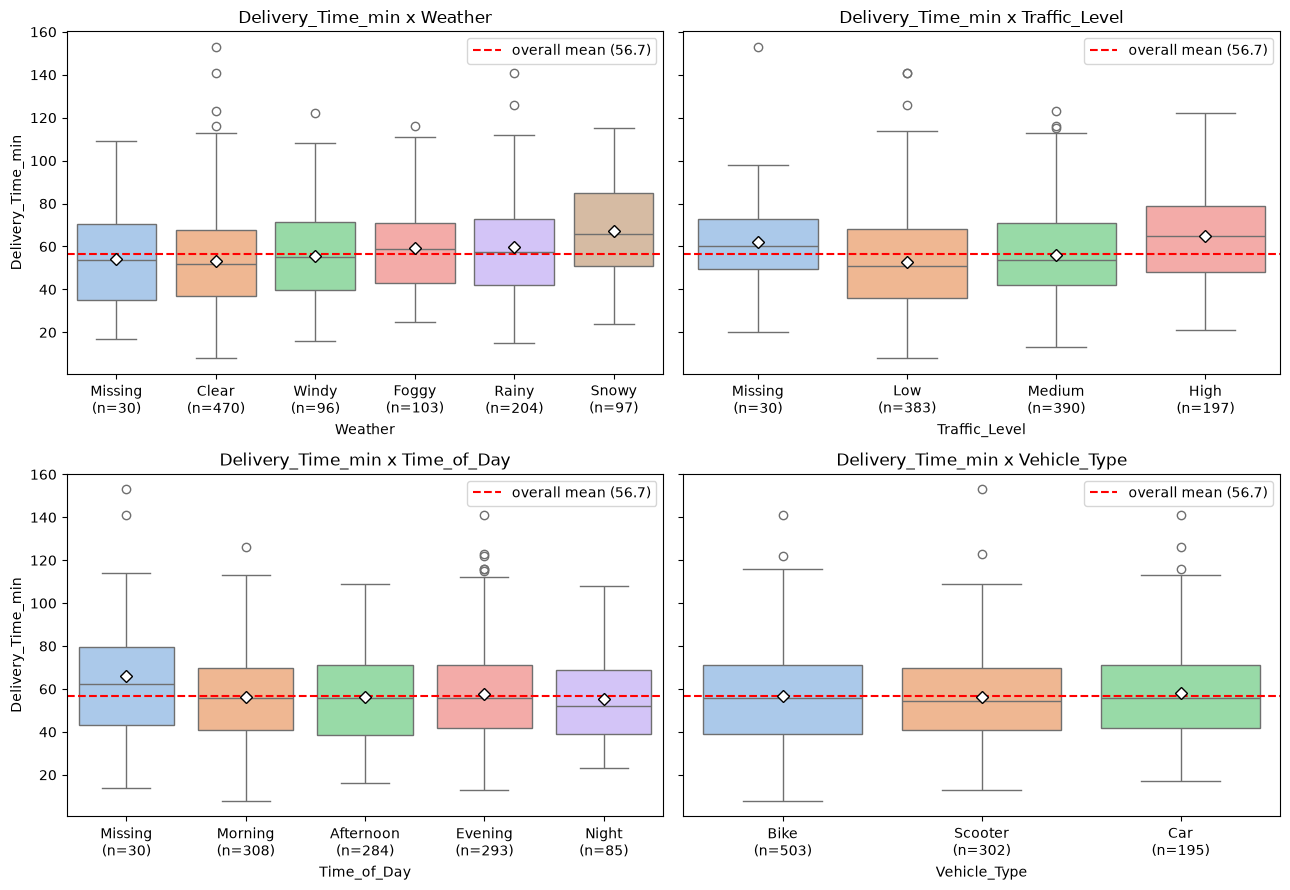

In [26]:

cat_cols = df_deliv_v2.select_dtypes(exclude=["int64","float64"]).drop(columns = ["Order_ID"]).columns.to_list()

orders = {
    "Weather":       ["Missing","Clear","Windy","Foggy","Rainy","Snowy"],
    "Traffic_Level": ["Missing","Low","Medium","High"],
    "Time_of_Day":   ["Missing","Morning","Afternoon","Evening","Night"],
    "Vehicle_Type":  ["Bike","Scooter","Car"],
}

overall_mean = df_deliv_v2[delivery_time].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
axes = axes.flatten()

for idx, cat in enumerate(cat_cols):
    data = df_deliv_v2.dropna(subset=[cat])
    counts = data[cat].value_counts()
    sns.boxplot(x=cat, y=delivery_time, data=data, order=orders[cat],
                hue=cat, hue_order=orders[cat], palette="pastel", legend=False,
                showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                ax=axes[idx])
    axes[idx].axhline(overall_mean, color="red", linestyle="--", label=f"overall mean ({overall_mean:.1f})")
    axes[idx].set_xticks(range(len(orders[cat])))
    axes[idx].set_xticklabels([f"{c}\n(n={counts[c]})" for c in orders[cat]])
    axes[idx].set_title(f"{delivery_time} x {cat}")
    axes[idx].set_xlabel(cat)
    axes[idx].set_ylabel(delivery_time)
    axes[idx].legend()

plt.tight_layout()
plt.show()

In [28]:
print(pd.crosstab(df_deliv_v2["Weather"],df_deliv_v2["Traffic_Level"],normalize="index").round(2)*100)

Traffic_Level  High   Low  Medium  Missing
Weather                                   
Clear          18.0  38.0    41.0      4.0
Foggy          20.0  46.0    33.0      1.0
Missing        20.0  30.0    50.0      0.0
Rainy          22.0  39.0    36.0      3.0
Snowy          21.0  45.0    31.0      3.0
Windy          24.0  27.0    46.0      3.0


In [33]:
for a, b in itertools.combinations(cat_cols, 2):
    ct = pd.crosstab(df_deliv_v2[a], df_deliv_v2[b])
    chi2, p, dof, exp = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{a} x {b}: V = {cramers_v:.3f}, p-value = {p:.3f}")

Weather x Traffic_Level: V = 0.076, p-value = 0.303
Weather x Time_of_Day: V = 0.057, p-value = 0.885
Weather x Vehicle_Type: V = 0.090, p-value = 0.098
Traffic_Level x Time_of_Day: V = 0.056, p-value = 0.671
Traffic_Level x Vehicle_Type: V = 0.070, p-value = 0.137
Time_of_Day x Vehicle_Type: V = 0.085, p-value = 0.069


## **ANOVA** & **CORRELATION HEATMAP** V2

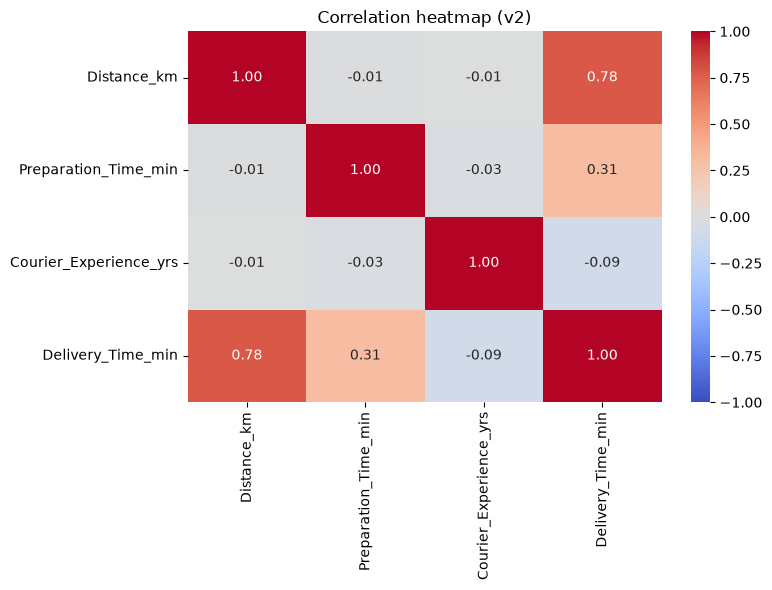

v2 R2 of Distance_km = 0.6100
v2 Q1 = 41.0, Q3 = 71.0, IQR = 30.0
v2 Fences: lower = -4.0, upper = 116.0
v2 Below the lower fence: 0 | Above the upper fence: 6
                    eta_squared                             p_value  \
target        Delivery_Time_min residual_distance Delivery_Time_min   
variable                                                              
Time_of_Day              0.0067            0.0130            0.1521   
Traffic_Level            0.0402            0.0858            0.0000   
Vehicle_Type             0.0012            0.0008            0.5549   
Weather                  0.0406            0.0586            0.0000   

                                 
target        residual_distance  
variable                         
Time_of_Day              0.0111  
Traffic_Level            0.0000  
Vehicle_Type             0.6686  
Weather                  0.0000  
                            features  n_rows  R2 (v2)
0                           Distance    1000    0.

In [45]:
anova_v2, r2_v2, outliers_v2 = full_check(df_deliv_v2, "v2")
print(anova_v2)
print(r2_v2)
print(outliers_v2)

* Cramér’s V between every pair of categorical variables is below 0.09 (all p > 0.05), in both v1 and v2. The categorical variables are independent of each other, so each one provides separate information</p> 
* The median creates a small spike at 5 years in the experience histogram (30 rows with the same value).</p>
* The only relevant change is **Time_of_Day**: its p-value drops from 0.14 to 0.011 after removing distance. This comes from the "Missing" group (mean about 66 min vs about 56), so missingness itself seems linked to slower deliveries. With 30 rows it may be chance, and I'll check it with cross-validation. 


## ANOVA & CORRELATION V3 
    running without the missing values

In [34]:
df_deliv_v3 = df_deliv_v1.dropna().copy()
print(df_deliv_v3.shape)  

(883, 9)


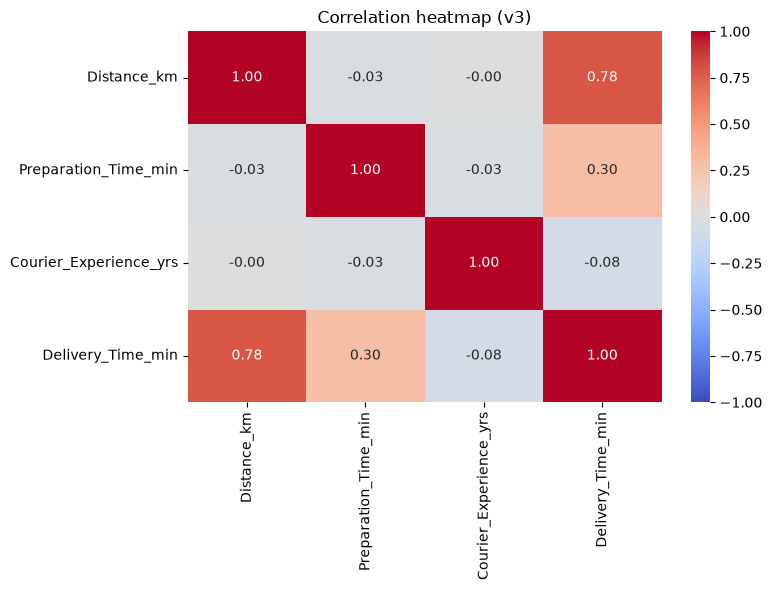

v3 R2 of Distance_km = 0.6134
v3 Q1 = 41.0, Q3 = 71.0, IQR = 30.0
v3 Fences: lower = -4.0, upper = 116.0
v3 Below the lower fence: 0 | Above the upper fence: 4
                    eta_squared                             p_value  \
target        Delivery_Time_min residual_distance Delivery_Time_min   
variable                                                              
Time_of_Day              0.0022            0.0040            0.5908   
Traffic_Level            0.0404            0.0960            0.0000   
Vehicle_Type             0.0017            0.0021            0.4798   
Weather                  0.0434            0.0632            0.0000   

                                 
target        residual_distance  
variable                         
Time_of_Day              0.3172  
Traffic_Level            0.0000  
Vehicle_Type             0.3918  
Weather                  0.0000  
                            features  n_rows  R2 (v3)
0                           Distance     883    0.

In [44]:
anova_v3, r2_v3,outliers_v3 = full_check(df_deliv_v3, "v3")
print(anova_v3)
print(r2_v3)
print(outliers_v3)

## Decision: impute, do not drop

I will not drop the rows with missing values. The dataset is small (1,000 rows), and dropping the 117 incomplete rows (11.7%) would leave 883 rows to train, which increases the risk of overfitting. Each column only has 3% missing values, and v1, v2 and v3 gave the same main conclusions in the EDA (the only difference was the p-value of **Time_of_Day** in v2, caused by the "Missing" group), so imputing seems to cost very little. I'll confirm this with cross-validation.</p>
- The imputation is done inside the modeling pipeline and fitted on the training folds only, to avoid leaking information from the test rows.</p>
- With cross-validation I'll compare the imputation options, and I'll check if the "Missing" level of **Time_of_Day** helps the predictions or is only noise.